# Practical 3A — Credit Card Fraud Autoencoder

Extracted from `3A.pdf`. Original displayed outputs omitted; executable Python code retained.

**Required local inputs:** `creditcard.csv`

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 30)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │             992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │             544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 30)                  │             990 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,054 (11.93 KB)

 Trainable params: 3,054 (11.93 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - loss: 0.5448 - val_loss: 0.3366
Epoch 2/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 0.2913 - val_loss: 0.2598
Epoch 3/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.2362 - val_loss: 0.2165
Epoch 4/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - loss: 0.2061 - val_loss: 0.1897
Epoch 5/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - loss: 0.1781 - val_loss: 0.1624
Epoch 6/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - loss: 0.1552 - val_loss: 0.1446
Epoch 7/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - loss: 0.1411 - val_loss: 0.1345
Epoch 8/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - loss: 0.1311 - val_loss: 0.1261
Epoch 9/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - loss: 0.1231 - val_loss: 0.1175
Epoch 10/10
800/800 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - loss: 0.1161 - val_loss: 0.1117
Reconstruction Error Threshold: 0.31505609070620916

Confusion Matrix:
[[54020  2844]
 [   16    82]]

Classification Report

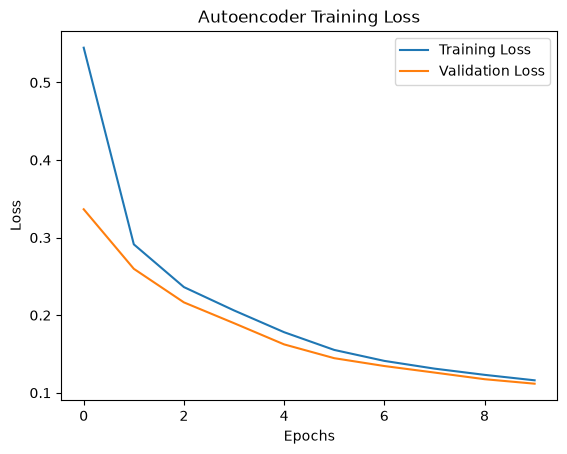

Total Transactions: 56962
Actual Fraud Transactions: 98
Detected Fraud Transactions: 2926


In [1]:
# 1. Import necessary packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
# 2. Load the dataset
data = pd.read_csv('LP_IV_Updated Datasets/LP_IV_Updated Datasets/AutoEncoder/CreditCard/creditcard.csv')
print(data.head())
print(data['Class'].value_counts())
# 3. Separate features and labels
X = data.drop('Class', axis=1)
y = data['Class']
# 4. Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# 5. Select only normal transactions for training
X_train_normal = X_train[y_train == 0]
# Scale the features
scaler = StandardScaler()
X_train_normal = scaler.fit_transform(X_train_normal)
X_test = scaler.transform(X_test)
# 6. Build the Autoencoder model
input_dim = X_train_normal.shape[1]
input_layer = Input(shape=(input_dim,))
# Encoder
encoded = Dense(32, activation='relu')(input_layer)
encoded = Dense(16, activation='relu')(encoded)
# Decoder
decoded = Dense(32, activation='relu')(encoded)
decoded = Dense(input_dim, activation='linear')(decoded)
autoencoder = Model(input_layer, decoded)
# 7. Compile the model
autoencoder.compile(
    optimizer='adam',
    loss='mse'
)
autoencoder.summary()
# 8. Train the Autoencoder
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=10,
    batch_size=256,
    validation_split=0.1,
    shuffle=True
)
# 9. Calculate reconstruction error
normal_test = X_test[y_test.values == 0]
normal_predictions = autoencoder.predict(normal_test, verbose=0)
normal_error = np.mean(
    np.square(normal_test - normal_predictions), axis=1
)
# Set threshold using 95th percentile of normal errors
threshold = np.percentile(normal_error, 95)
print("Reconstruction Error Threshold:", threshold)
# 10. Predict fraud transactions
predictions = autoencoder.predict(X_test, verbose=0)
errors = np.mean(
    np.square(X_test - predictions), axis=1
)
# Error above threshold means fraud
y_pred = (errors > threshold).astype(int)
# 11. Evaluate the model
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
# 12. Plot training loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()
# 13. Display fraud detection results
print("Total Transactions:", len(y_test))
print("Actual Fraud Transactions:", sum(y_test))
print("Detected Fraud Transactions:", sum(y_pred))
